EDA, первичная работа в `experiments.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path.cwd()
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

In [2]:
print('Train:', train.shape)
print('Test:', test.shape)
train.head()

Train: (891, 12)
Test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Значение колонок

- PassengerId — идентификатор пассажира.
- Survived    — целевая переменная: 0 — не выжил, 1 — выжил; только в train.
- Pclass      — класс билета: 1 — первый, 2 — второй, 3 — третий.
- Name        — полное имя пассажира, включая обращение (Mr, Mrs, Miss и др.).
- Sex         — пол пассажира.
- Age         — возраст в годах; у младенцев может быть дробным.
- SibSp       — количество братьев, сестёр и супругов на борту.
- Parch       — количество родителей и детей на борту.
- Ticket      — номер билета.
- Fare        — стоимость билета.
- Cabin       — номер каюты.
- Embarked    — порт посадки: C — Cherbourg, Q — Queenstown, S — Southampton.

In [3]:
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Пропуски и дубликаты

In [4]:
missing = pd.DataFrame({
    'train_count': train.isna().sum(),
    'train_percent': train.isna().mean() * 100,
    'test_count': test.isna().sum(),
    'test_percent': test.isna().mean() * 100,
})
missing.round(2)

,train_count,train_percent,test_count,test_percent
Age,177,19.87,86.0,20.57
Cabin,687,77.10,327.0,78.23
Embarked,2,0.22,0.0,0.00
Fare,0,0.00,1.0,0.24
Name,0,0.00,0.0,0.00
Parch,0,0.00,0.0,0.00
PassengerId,0,0.00,0.0,0.00
Pclass,0,0.00,0.0,0.00
Sex,0,0.00,0.0,0.00
SibSp,0,0.00,0.0,0.00


Больше всего пропусков в Cabin. В Age нет примерно пятой части значений. Ещё два пропуска в Embarked у train и один в Fare у test. Это NaN, а не нули. Для первого обучения пропуски буду заполнять внутри каждого фолда; Cabin пока не беру.

In [5]:
for name, frame in [('train', train), ('test', test)]:
    print(name, 'duplicates:', frame.duplicated().sum())
    print(name, 'unique PassengerId:', frame['PassengerId'].is_unique)

train duplicates: 0
train unique PassengerId: True
test duplicates: 0
test unique PassengerId: True


Полных дубликатов нет, PassengerId уникален в обеих таблицах. Сам идентификатор в первый набор признаков не включаю.

## Целевая переменная и пол

In [6]:
pd.DataFrame({
    'count': train['Survived'].value_counts(),
    'percent': train['Survived'].value_counts(normalize=True) * 100,
}).round(2)

,count,percent
Survived,,
0,549,61.62
1,342,38.38


Выжили 38,38% пассажиров train. Постоянный ответ «не выжил» уже даёт около 62% accuracy

        passengers  survival_rate
Sex                              
female         314       0.742038
male           577       0.188908


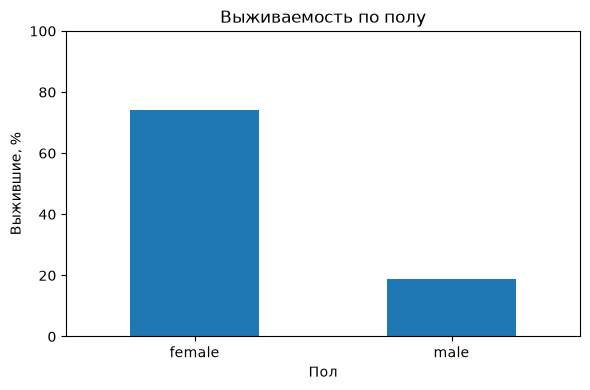

In [7]:
sex_summary = train.groupby('Sex')['Survived'].agg(passengers='count', survival_rate='mean')
print(sex_summary)
ax = sex_summary['survival_rate'].mul(100).plot.bar(rot=0, figsize=(6, 4))
ax.set(title='Выживаемость по полу', xlabel='Пол', ylabel='Выжившие, %', ylim=(0, 100))
plt.tight_layout()
plt.show()

Женщин выжило больше и по количеству, и по доле внутри группы: 74,20% против 18,89% у мужчин. Эти проценты не складываются в 100%: каждый рассчитан от своего количества пассажиров.

## Возраст

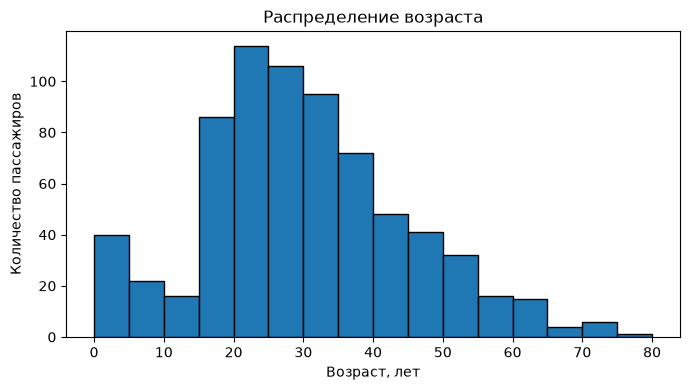

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(train['Age'].dropna(), bins=range(0, 85, 5), edgecolor='black')
plt.xlabel('Возраст, лет')
plt.ylabel('Количество пассажиров')
plt.title('Распределение возраста')
plt.tight_layout()
plt.show()

Основная масса пассажиров с известным возрастом — молодые взрослые. 


## Класс билета

        passengers  survival_rate
Pclass                           
1              216       0.629630
2              184       0.472826
3              491       0.242363


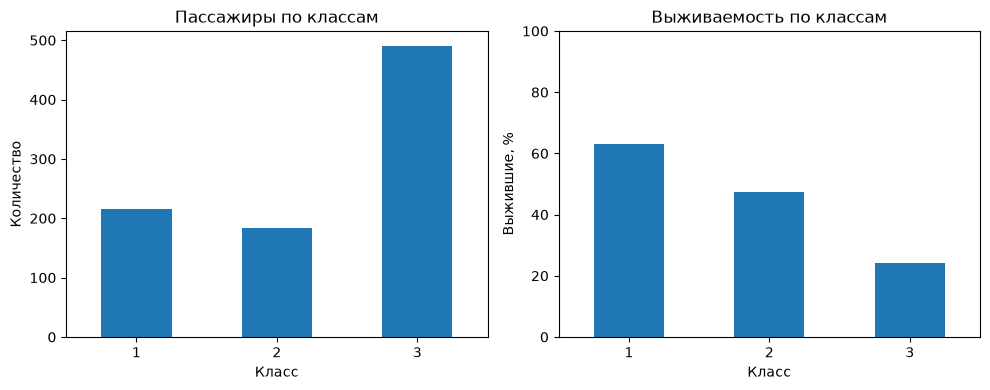

In [9]:
class_summary = train.groupby('Pclass')['Survived'].agg(passengers='count', survival_rate='mean')
print(class_summary)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
class_summary['passengers'].plot.bar(ax=axes[0], rot=0)
class_summary['survival_rate'].mul(100).plot.bar(ax=axes[1], rot=0)
axes[0].set(title='Пассажиры по классам', xlabel='Класс', ylabel='Количество')
axes[1].set(title='Выживаемость по классам', xlabel='Класс', ylabel='Выжившие, %', ylim=(0, 100))
plt.tight_layout()
plt.show()

Третий класс самый многочисленный, затем идут первый и второй. Доля выживших снижается от первого класса к третьему. 

## Стоимость билета

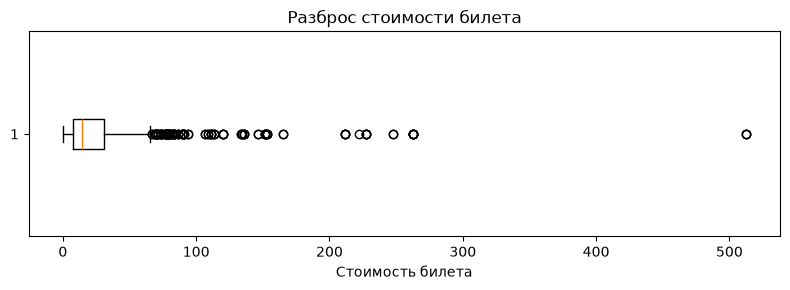

In [10]:
plt.figure(figsize=(8, 3))
plt.boxplot(train['Fare'].dropna(), orientation='horizontal')
plt.xlabel('Стоимость билета')
plt.title('Разброс стоимости билета')
plt.tight_layout()
plt.show()

Большинство билетов относительно недорогие, но есть длинный хвост вплоть до 500

In [11]:
fare_groups = pd.cut(train['Fare'], bins=[0, 10, 30, 100, float('inf')], include_lowest=True)
train.groupby(fare_groups, observed=True)['Survived'].agg(passengers='count', survival_rate='mean')

,passengers,survival_rate
Fare,,
"(-0.001, 10.0]",336,0.199405
"(10.0, 30.0]",321,0.433022
"(30.0, 100.0]",181,0.535912
"(100.0, inf]",53,0.735849


У самых дешёвых билетов доля выживших ниже.Цена связана с классом билета, поэтому  нельзя сказать, что именно высокая цена объясняет выживание.

## Порт посадки

In [12]:
train.groupby('Embarked')['Survived'].agg(passengers='count', survival_rate='mean')

,passengers,survival_rate
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


У пассажиров из C доля выживших выше, чем из Q и S. 

## Родственники на борту

In [13]:
for feature in ['SibSp', 'Parch']:
    print(feature)
    display(train.groupby(feature)['Survived'].agg(passengers='count', survival_rate='mean').round(3))

SibSp


,passengers,survival_rate
SibSp,,
0,608,0.345
1,209,0.536
2,28,0.464
3,16,0.250
4,18,0.167
5,5,0.000
8,7,0.000


Parch


,passengers,survival_rate
Parch,,
0,678,0.344
1,118,0.551
2,80,0.500
3,5,0.600
4,4,0.000
5,5,0.200
6,1,0.000


При одном родственнике доля выживших выше, чем при нуле. Для SibSp при больших значениях она снижается. 

## Сравнение train и test

In [113]:
for feature in ['Sex', 'Pclass', 'Embarked']:
    print(feature)
    display(pd.DataFrame({
        'train_percent': train[feature].value_counts(normalize=True, dropna=False) * 100,
        'test_percent': test[feature].value_counts(normalize=True, dropna=False) * 100,
    }).round(1))


Sex


,train_percent,test_percent
Sex,,
male,64.8,63.6
female,35.2,36.4


Pclass


,train_percent,test_percent
Pclass,,
3,55.1,52.2
1,24.2,25.6
2,20.7,22.2


Embarked


,train_percent,test_percent
Embarked,,
C,18.9,24.4
Q,8.6,11.0
S,72.3,64.6
NaN,0.2,NaN


Распределения в целом похожи, сдвига не видно.

#Пайплайн


Числовые признаки: Age, SibSp, Parch, Fare. Категориальные: Pclass, Sex, Embarked. Пропуски заполняются медианой или самым частым значением только по обучающей части фолда. Для логрегрессии, KNN и MLP добавляю StandardScaler. 